# LoRA vs LoRA+ Experimental Evaluation: GPT-2 on SST-2

This notebook follows the Ram-aligned screening, selection, final multi-seed, and convergence workflow for the GPT-2/SST-2 part of the project.


In [5]:
from google.colab import files
import io
import os
import shutil
import zipfile

uploaded = files.upload()

zip_name = next(
    name for name in uploaded
    if name.lower().endswith(".zip")
)

shutil.rmtree("/content/LoRA_Plus_Project", ignore_errors=True)

with zipfile.ZipFile(io.BytesIO(uploaded[zip_name])) as archive:
    archive.extractall("/content")

os.rename(
    "/content/gpt2-sst2-lora-plus",
    "/content/LoRA_Plus_Project"
)

print("Project extracted successfully.")
print(os.listdir("/content/LoRA_Plus_Project"))

Saving GPT2-SST2-LoRA-Plus.zip to GPT2-SST2-LoRA-Plus.zip
Project extracted successfully.
['requirements.txt', 'config.py', 'README.md', 'evaluate_results.py', 'notebooks', 'utils.py', 'train.py', 'model.py']


In [1]:
# Cell 1: Mount Drive and initialize the GPT-2 project

from google.colab import drive
drive.mount('/content/drive')

import os
import sys

PROJECT_DIR = '/content/LoRA_Plus_Project'
assert os.path.isfile(f'{PROJECT_DIR}/config.py'), (
    'Extract the GPT2-SST2 project ZIP at /content/LoRA_Plus_Project first.'
)

%cd /content/LoRA_Plus_Project
if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)
os.makedirs(f'{PROJECT_DIR}/results', exist_ok=True)

print('Project initialized successfully!')
print('Project directory:', PROJECT_DIR)


Mounted at /content/drive


AssertionError: Extract the GPT2-SST2 project ZIP at /content/LoRA_Plus_Project first.

## 2. Install Required Dependencies

Install the libraries required for model fine-tuning,
LoRA/LoRA+ optimization, dataset processing, and evaluation.

In [8]:
%pip install -r requirements.txt
%pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


## 3. Select Model and Dataset

Specify the pretrained model and GLUE benchmark dataset
for the current experiment.

In [3]:
MODEL_NAME = 'gpt2'
DATASET_NAME = 'sst2'

print('Model:', MODEL_NAME)
print('Dataset:', DATASET_NAME)


Model: gpt2
Dataset: sst2


## 4. Import Shared Project Modules

Import the reusable configuration, dataset preparation,
training, and evaluation functions.

In [9]:
from config import (
    COMMON_CONFIG,
    LORA_LEARNING_RATES,
    LORAPLUS_CONFIGS,
    get_output_dir
)

from utils import prepare_dataset

from train import run_experiment

from evaluate_results import (
    select_best,
    summarize_final,
    plot_convergence
)

print("All project modules imported successfully!")

All project modules imported successfully!


## 5. Dataset Loading and Preprocessing

Load the selected GLUE dataset and tokenize the input text
using the tokenizer corresponding to the selected model.

The dataset is prepared once and reused across all runs.

In [10]:
tokenizer, train_dataset, eval_dataset, data_collator = (
    prepare_dataset(
        model_name=MODEL_NAME,
        dataset_name=DATASET_NAME,
        pilot=False
    )
)

print("Training examples:", len(train_dataset))
print("Validation examples:", len(eval_dataset))

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

... (9 outputs left out)

Map:   0%|          | 0/67349 [00:00<?, ? examples/s]

Map:   0%|          | 0/872 [00:00<?, ? examples/s]

Map:   0%|          | 0/1821 [00:00<?, ? examples/s]

Model: gpt2
Dataset: sst2
Training examples: 67349
Validation examples: 872
Training examples: 67349
Validation examples: 872


## 6. Sanity Test (50 Training Steps)

Verify model initialization, LoRA adapter configuration,
optimizer parameter groups, GPU compatibility, and
metric computation before running full experiments.

In [ ]:
test = run_experiment(
    model_name=MODEL_NAME,
    dataset_name=DATASET_NAME,
    tokenizer=tokenizer,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    data_collator=data_collator,
    lam=4,
    seed=COMMON_CONFIG['screening_seed'],
    epochs=COMMON_CONFIG['epochs'],
    base_lr=1e-4,
    stage='test',
    max_steps=50
)

print(test)


model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] GPT2ForSequenceClassification LOAD REPORT from: gpt2
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.13/dist-packages/peft/tuners/lora/layer.py:2760: UserWarning: fan_in_fan_out is set to False but the target module is `Conv1D`. Setting fan_in_fan_out to True.
  warnings.warn(


trainable params: 1,181,184 || all params: 125,622,528 || trainable%: 0.9403
A 516096 0.0001
B 663552 0.0004
other 1536 0.0001


Step,Training Loss,Validation Loss,Accuracy,F1,F1 Macro
50,2.378869,0.867932,0.487385,0.602667,0.440267


Training Loss,Validation Loss,Step,Accuracy,F1,F1 Macro
2.378869,0.867932,50,0.487385,0.602667,0.440267


{'stage': 'test', 'model': 'gpt2', 'model_key': 'gpt2', 'dataset': 'sst2', 'method': 'LoRA+', 'lam': 4, 'eta_A': 0.0001, 'eta_B': 0.0004, 'seed': 42, 'epochs': 3, 'batch_size': 32, 'max_steps': 50, 'train_examples': 67349, 'eval_examples': 872, 'final_acc': 0.4873853211009174, 'final_f1': 0.6026666666666667, 'final_f1_macro': 0.4402670974690361, 'best_acc': 0.4873853211009174, 'best_f1': 0.6026666666666667, 'best_f1_macro': 0.4402670974690361, 'final_eval_loss': 0.8679323792457581, 'last_train_loss': 2.3788691711425782, 'train_runtime_s': 9.0421, 'samples_per_s': 176.951, 'total_steps': 50, 'peak_mem_gb': 2.424920576, 'trainable_params': 1181184, 'torch': '2.14.1+cu130', 'transformers': '5.22.1', 'peft': '0.21.2'}


## 7. Hyperparameter Screening - Standard LoRA

Evaluate standard LoRA using three learning rates.

Both adapter matrices A and B use the same learning rate.
Each configuration is trained for three epochs using seed 42.

In [ ]:
for lr in LORA_LEARNING_RATES:

    run_experiment(
        model_name=MODEL_NAME,
        dataset_name=DATASET_NAME,
        tokenizer=tokenizer,
        train_dataset=train_dataset,
        eval_dataset=eval_dataset,
        data_collator=data_collator,
        lam=1,
        seed=COMMON_CONFIG["screening_seed"],
        epochs=COMMON_CONFIG["epochs"],
        base_lr=lr,
        stage="screening"
    )

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] GPT2ForSequenceClassification LOAD REPORT from: gpt2
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.13/dist-packages/peft/tuners/lora/layer.py:2760: UserWarning: fan_in_fan_out is set to False but the target module is `Conv1D`. Setting fan_in_fan_out to True.
  warnings.warn(


trainable params: 1,181,184 || all params: 125,622,528 || trainable%: 0.9403
A 516096 0.0001
B 663552 0.0001
other 1536 0.0001


Step,Training Loss,Validation Loss,Accuracy,F1,F1 Macro
200,0.604470,0.457471,0.794725,0.813736,0.792564
400,0.401755,0.319102,0.871560,0.868235,0.871478
600,0.349727,0.294101,0.892202,0.893905,0.892174
800,0.339948,0.300493,0.883028,0.890323,0.882508
1000,0.331165,0.327477,0.866972,0.878151,0.865843
1200,0.328337,0.273997,0.896789,0.901099,0.896593
1400,0.308532,0.280058,0.895642,0.899448,0.895493
1600,0.334079,0.276777,0.893349,0.899023,0.893011
1800,0.316317,0.264415,0.907110,0.909295,0.907056
2000,0.302412,0.274752,0.894495,0.900433,0.894119


Training Loss,Validation Loss,Step,Accuracy,F1,F1 Macro
0.252914,0.250925,6315,0.910550,0.912556,0.910503


Saved result: /content/drive/MyDrive/LoRA_Plus_Project/modular_v2/gpt2/sst2/runs/gpt2_sst2_lam1_lr0.0001_seed42_ep3_bs32_steps-1_screening.json


... (8 outputs left out)

trainable params: 1,181,184 || all params: 125,622,528 || trainable%: 0.9403
A 516096 0.0004
B 663552 0.0004
other 1536 0.0001


Step,Training Loss,Validation Loss,Accuracy,F1,F1 Macro
200,0.422570,0.343353,0.846330,0.862140,0.844282
400,0.392955,0.279483,0.887615,0.892779,0.887353
600,0.325797,0.270164,0.897936,0.901221,0.897823
800,0.310412,0.273687,0.899083,0.901124,0.899040
1000,0.297915,0.349483,0.868119,0.879328,0.866971
1200,0.299403,0.266993,0.901376,0.904018,0.901301
1400,0.263592,0.259531,0.904817,0.909290,0.904584
1600,0.293132,0.245733,0.913991,0.916574,0.913908
1800,0.272059,0.255186,0.908257,0.911504,0.908133
2000,0.267270,0.240220,0.911697,0.915292,0.911538


Training Loss,Validation Loss,Step,Accuracy,F1,F1 Macro
0.198849,0.270989,6315,0.912844,0.915743,0.912741


Saved result: /content/drive/MyDrive/LoRA_Plus_Project/modular_v2/gpt2/sst2/runs/gpt2_sst2_lam1_lr0.0004_seed42_ep3_bs32_steps-1_screening.json


## 8. Hyperparameter Screening - LoRA+

Evaluate LoRA+ using six combinations of base learning
rates and learning-rate ratios.

Matrix B uses a larger learning rate than matrix A:

eta_B = lambda * eta_A

Each configuration is trained for three epochs using seed 42.

In [ ]:
for lr, ratio in LORAPLUS_CONFIGS:

    run_experiment(
        model_name=MODEL_NAME,
        dataset_name=DATASET_NAME,
        tokenizer=tokenizer,
        train_dataset=train_dataset,
        eval_dataset=eval_dataset,
        data_collator=data_collator,
        lam=ratio,
        seed=COMMON_CONFIG["screening_seed"],
        epochs=COMMON_CONFIG["epochs"],
        base_lr=lr,
        stage="screening"
    )

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] GPT2ForSequenceClassification LOAD REPORT from: gpt2
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.13/dist-packages/peft/tuners/lora/layer.py:2760: UserWarning: fan_in_fan_out is set to False but the target module is `Conv1D`. Setting fan_in_fan_out to True.
  warnings.warn(


trainable params: 1,181,184 || all params: 125,622,528 || trainable%: 0.9403
A 516096 0.0001
B 663552 0.0004
other 1536 0.0001


Step,Training Loss,Validation Loss,Accuracy,F1,F1 Macro
200,0.434491,0.330636,0.855505,0.861842,0.855200
400,0.384852,0.299444,0.883028,0.879717,0.882939
600,0.334656,0.277999,0.893349,0.896089,0.893274
800,0.328951,0.281209,0.891055,0.894562,0.890934
1000,0.315129,0.354700,0.862385,0.875260,0.860904
1200,0.309652,0.253562,0.907110,0.909091,0.907066
1400,0.284396,0.274126,0.900229,0.905742,0.899887
1600,0.312148,0.261404,0.902523,0.906696,0.902328
1800,0.295767,0.259729,0.905963,0.906393,0.905961
2000,0.283110,0.270961,0.905963,0.910870,0.905678


Training Loss,Validation Loss,Step,Accuracy,F1,F1 Macro
0.221214,0.257858,6315,0.922018,0.923767,0.921977


Saved result: /content/drive/MyDrive/LoRA_Plus_Project/modular_v2/gpt2/sst2/runs/gpt2_sst2_lam4_lr0.0001_seed42_ep3_bs32_steps-1_screening.json


... (26 outputs left out)

trainable params: 1,181,184 || all params: 125,622,528 || trainable%: 0.9403
A 516096 0.0002
B 663552 0.0032
other 1536 0.0001


Step,Training Loss,Validation Loss,Accuracy,F1,F1 Macro
200,0.391112,0.306130,0.875000,0.884166,0.874212
400,0.356527,0.272965,0.892202,0.888889,0.892106
600,0.303087,0.254569,0.905963,0.909091,0.905852
800,0.301948,0.252066,0.909404,0.910936,0.909377
1000,0.286065,0.301247,0.887615,0.897275,0.886612
1200,0.278601,0.264284,0.903670,0.908297,0.903424
1400,0.248620,0.233355,0.916284,0.918979,0.916192
1600,0.280156,0.238164,0.916284,0.918979,0.916192
1800,0.262781,0.248143,0.907110,0.907429,0.907109
2000,0.242064,0.240444,0.915138,0.919565,0.914880


Training Loss,Validation Loss,Step,Accuracy,F1,F1 Macro
0.149023,0.271110,6315,0.917431,0.919643,0.917369


Saved result: /content/drive/MyDrive/LoRA_Plus_Project/modular_v2/gpt2/sst2/runs/gpt2_sst2_lam16_lr0.0002_seed42_ep3_bs32_steps-1_screening.json


## 9. Best Hyperparameter Selection

Select the best standard LoRA and LoRA+ configurations
based on validation performance.

SST-2 uses accuracy as the primary metric.
QQP uses binary F1 as the primary metric.

In [10]:
best_lora, best_loraplus = select_best(
    MODEL_NAME,
    DATASET_NAME
)

BEST_LORA_LR = float(best_lora["eta_A"])

BEST_LORAPLUS_LR = float(best_loraplus["eta_A"])
BEST_LAM = int(best_loraplus["lam"])

print("Best LoRA learning rate:", BEST_LORA_LR)
print("Best LoRA+ learning rate:", BEST_LORAPLUS_LR)
print("Best LoRA+ ratio:", BEST_LAM)


Best standard LoRA:
eta_A          0.0002
eta_B          0.0002
final_acc    0.919725
Name: 1, dtype: object

Best LoRA+:
eta_A          0.0001
eta_B          0.0008
lam                 8
final_acc    0.923165
Name: 4, dtype: object
Best LoRA learning rate: 0.0002
Best LoRA+ learning rate: 0.0001
Best LoRA+ ratio: 8


## 10. Final Multi-Seed Experiments

Evaluate the selected LoRA and LoRA+ configurations
across three random seeds: 42, 43, and 44.

Each run trains a fresh model for three epochs.

In [14]:
for seed in COMMON_CONFIG["seeds"]:

    # Standard LoRA
    run_experiment(
        model_name=MODEL_NAME,
        dataset_name=DATASET_NAME,
        tokenizer=tokenizer,
        train_dataset=train_dataset,
        eval_dataset=eval_dataset,
        data_collator=data_collator,
        lam=1,
        seed=seed,
        epochs=COMMON_CONFIG["epochs"],
        base_lr=BEST_LORA_LR,
        stage="final"
    )

    # LoRA+
    run_experiment(
        model_name=MODEL_NAME,
        dataset_name=DATASET_NAME,
        tokenizer=tokenizer,
        train_dataset=train_dataset,
        eval_dataset=eval_dataset,
        data_collator=data_collator,
        lam=BEST_LAM,
        seed=seed,
        epochs=COMMON_CONFIG["epochs"],
        base_lr=BEST_LORAPLUS_LR,
        stage="final"
    )

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] GPT2ForSequenceClassification LOAD REPORT from: gpt2
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.13/dist-packages/peft/tuners/lora/layer.py:2760: UserWarning: fan_in_fan_out is set to False but the target module is `Conv1D`. Setting fan_in_fan_out to True.
  warnings.warn(


trainable params: 1,181,184 || all params: 125,622,528 || trainable%: 0.9403
A 516096 0.0002
B 663552 0.0002
other 1536 0.0001


Step,Training Loss,Validation Loss,Accuracy,F1,F1 Macro
200,0.438601,0.334050,0.855505,0.861842,0.855200
400,0.381614,0.301041,0.881881,0.878681,0.881799
600,0.333283,0.280013,0.894495,0.898004,0.894370
800,0.330235,0.281857,0.894495,0.897778,0.894387
1000,0.314254,0.358328,0.857798,0.871369,0.856197
1200,0.311423,0.255525,0.903670,0.906250,0.903597
1400,0.286492,0.276116,0.894495,0.900648,0.894089
1600,0.313141,0.258113,0.905963,0.909890,0.905784
1800,0.298735,0.253939,0.907110,0.908475,0.907089
2000,0.284707,0.265929,0.907110,0.911668,0.906862


... (28 outputs left out)

trainable params: 1,181,184 || all params: 125,622,528 || trainable%: 0.9403
A 516096 0.0001
B 663552 0.0008
other 1536 0.0001


Step,Training Loss,Validation Loss,Accuracy,F1,F1 Macro
200,0.417043,0.320624,0.869266,0.877155,0.868725
400,0.347211,0.305235,0.892202,0.896476,0.892018
600,0.324611,0.294104,0.884174,0.890574,0.883777
800,0.317334,0.260342,0.895642,0.894798,0.895635
1000,0.310165,0.259690,0.899083,0.902004,0.898993
1200,0.306998,0.264644,0.901376,0.902935,0.901351
1400,0.300237,0.261255,0.907110,0.907003,0.907110
1600,0.271362,0.248196,0.912844,0.913043,0.912844
1800,0.262245,0.261790,0.913991,0.916759,0.913896
2000,0.258272,0.249957,0.910550,0.909931,0.910546


Training Loss,Validation Loss,Step,Accuracy,F1,F1 Macro
0.207242,0.256253,6315,0.913991,0.916759,0.913896


Saved result: /content/drive/MyDrive/LoRA_Plus_Project/modular_v2/gpt2/sst2/runs/gpt2_sst2_lam8_lr0.0001_seed44_ep3_bs32_steps-1_final.json


## 11. Final Performance Comparison

Aggregate results across three random seeds.

Report mean and standard deviation for accuracy,
F1, validation loss, training runtime, GPU memory,
and trainable parameter count.

In [15]:
summary = summarize_final(
    MODEL_NAME,
    DATASET_NAME
)

display(summary)


Best standard LoRA:
eta_A          0.0002
eta_B          0.0002
final_acc    0.919725
Name: 1, dtype: object

Best LoRA+:
eta_A          0.0001
eta_B          0.0008
lam                 8
final_acc    0.923165
Name: 4, dtype: object

Final results:
                  final_acc            final_f1           final_f1_macro           final_eval_loss           train_runtime_s           peak_mem_gb           trainable_params     
                       mean       std      mean       std           mean       std            mean       std            mean       std        mean       std             mean  std
method lam eta_A                                                                                                                                                                  
LoRA   1   0.0002  0.917049  0.002387  0.919365  0.002065       0.916980  0.002405        0.252428  0.009836      854.947400  1.776795    2.620470  0.005216        1181184.0  0.0
LoRA+  8   0.0001  0.918196  0.004

final_acc            final_f1           final_f1_macro  \
                       mean       std      mean       std           mean   
method lam eta_A                                                           
LoRA   1   0.0002  0.917049  0.002387  0.919365  0.002065       0.916980   
LoRA+  8   0.0001  0.918196  0.004635  0.920398  0.004185       0.918132   

                            final_eval_loss           train_runtime_s  \
                        std            mean       std            mean   
method lam eta_A                                                        
LoRA   1   0.0002  0.002405        0.252428  0.009836      854.947400   
LoRA+  8   0.0001  0.004658        0.254590  0.002138      854.880867   

                            peak_mem_gb           trainable_params       
                        std        mean       std             mean  std  
method lam eta_A                                                         
LoRA   1   0.0002  1.776795    2.620470  0.005216        1181184.0  0.0  
LoRA+  8   0.0001  1.032522    2.621884  0.004826        1181184.0  0.0

## 12. Convergence Analysis

Compare standard LoRA and LoRA+ convergence using
validation performance against optimizer steps.

Display mean performance across three seeds,
with standard-deviation bands.


Best standard LoRA:
eta_A          0.0002
eta_B          0.0002
final_acc    0.919725
Name: 1, dtype: object

Best LoRA+:
eta_A          0.0001
eta_B          0.0008
lam                 8
final_acc    0.923165
Name: 4, dtype: object


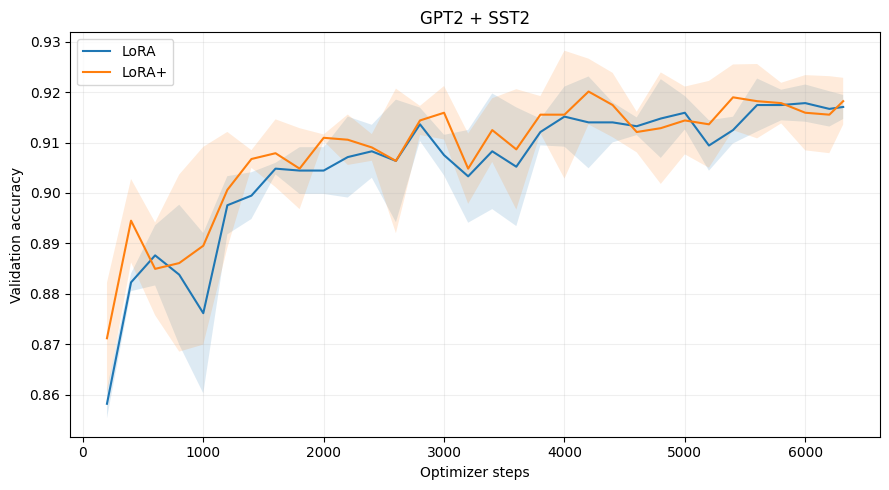

Saved: /content/drive/MyDrive/LoRA_Plus_Project/modular_v2/gpt2/sst2/convergence.png


In [11]:
plot_convergence(
    MODEL_NAME,
    DATASET_NAME
)

## Download the experiment results as zip

In [ ]:
from pathlib import Path
from google.colab import files
import zipfile

# Automatically select SST-2 or QQP
root = get_output_dir(MODEL_NAME, DATASET_NAME)

assert root.exists(), "Results directory does not exist"

# Create ZIP file outside the results directory
zip_path = Path(
    f"/content/{MODEL_NAME}_{DATASET_NAME}_results.zip"
)

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for path in root.rglob("*"):

        if path.is_file() and "checkpoints" not in path.parts:
            zipf.write(
                path,
                arcname=path.relative_to(root)
            )

print("Backup created:", zip_path)
print("Size:", round(zip_path.stat().st_size / 1024**2, 2), "MB")

# Download ZIP to your laptop
files.download(str(zip_path))

## 13. Discnnect Colab GPU


In [2]:
# Run ONLY after every JSON, CSV, summary, and convergence plot is saved.
from google.colab import runtime
runtime.unassign()
